In [311]:
import numpy as np
import scipy
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# this ipynb in the udemy course on credit risk that i am tryjnig to do that
# [Credit Risk Modeling in Python](https://www.udemy.com/course/credit-risk-modeling-in-python/?couponCode=KEEPLEARNING)

In [312]:
df = pd.read_csv(r"C:\Users\MohammadAmin\Desktop\projects\credit-risk-modeling\data\raw\loan_data_2007_2014.csv")


C:\Users\MohammadAmin\AppData\Local\Temp\ipykernel_20568\501861471.py:1: DtypeWarning: Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\MohammadAmin\Desktop\projects\credit-risk-modeling\data\raw\loan_data_2007_2014.csv")


In [313]:
df.shape


(466285, 75)

In [314]:
pd.set_option('display.max_columns', None)
df.head()


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,NaN,10+ years,RENT,24000.0,Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.0,Jan-85,1.0,NaN,NaN,3.0,0.0,13648,83.7,9.0,f,0.0,0.0,5861.071414,5831.78,5000.00,861.07,0.00,0.00,0.00,Jan-15,171.62,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,Ryder,< 1 year,RENT,30000.0,Source Verified,Dec-11,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.0,Apr-99,5.0,NaN,NaN,3.0,0.0,1687,9.4,4.0,f,0.0,0.0,1008.710000,1008.71,456.46,435.17,0.00,117.08,1.11,Apr-13,119.66,NaN,Sep-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,RENT,12252.0,Not Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.0,Nov-01,2.0,NaN,NaN,2.0,0.0,2956,98.5,10.0,f,0.0,0.0,3003.653644,3003.65,2400.00,603.65,0.00,0.00,0.00,Jun-14,649.91,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,RENT,49200.0,Source Verified,Dec-11,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > to pay for prop...,other,personel,917xx,CA,20.00,0.0,Feb-96,1.0,35.0,NaN,10.0,0.0,5598,21.0,37.0,f,0.0,0.0,12226.302210,12226.30,10000.00,2209.33,16.97,0.00,0.00,Jan-15,357.48,NaN,Jan-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,University Medical Group,1 year,RENT,80000.0,Source Verified,Dec-11,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/21/11 > I plan on combi...,other,Personal,972xx,OR,17.94,0.0,Jan-96,0.0,38.0,NaN,15.0,0.0,27783,53.9,38.0,f,766.9,766.9,3242.170000,3242.17,2233.10,1009.07,0.00,0.00,0.00,Jan-16,67.79,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [315]:
df.tail()


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
466280,466280,8598660,1440975,18400,18400,18400.0,60 months,14.47,432.64,C,C2,Financial Advisor,4 years,MORTGAGE,110000.0,Source Verified,Jan-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,773xx,TX,19.85,0.0,Apr-03,2.0,NaN,NaN,18.0,0.0,23208,77.6,36.0,w,12574.00,12574.00,10383.360000,10383.36,5826.00,4557.36,0.0,0.0,0.0,Jan-16,432.64,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,294998.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29900.0,NaN,NaN,NaN
466281,466281,9684700,11536848,22000,22000,22000.0,60 months,19.97,582.50,D,D5,Chief of Interpretation (Park Ranger),10+ years,MORTGAGE,78000.0,Verified,Jan-14,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,NaN,debt_consolidation,Debt consolidation,377xx,TN,18.45,0.0,Jun-97,5.0,NaN,116.0,18.0,1.0,18238,46.3,30.0,f,0.00,0.00,4677.920000,4677.92,1837.04,2840.88,0.0,0.0,0.0,Dec-14,17.50,NaN,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,221830.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39400.0,NaN,NaN,NaN
466282,466282,9584776,11436914,20700,20700,20700.0,60 months,16.99,514.34,D,D1,patrol,7 years,MORTGAGE,46000.0,Verified,Jan-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/06/13 > I am going to c...,debt_consolidation,Debt consolidation,458xx,OH,25.65,0.0,Dec-01,2.0,65.0,NaN,18.0,0.0,6688,51.1,43.0,f,14428.31,14428.31,12343.980000,12343.98,6271.69,6072.29,0.0,0.0,0.0,Jan-16,514.34,Feb-16,Dec-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,73598.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13100.0,NaN,NaN,NaN
466283,466283,9604874,11457002,2000,2000,2000.0,36 months,7.90,62.59,A,A4,Server Engineer Lead,3 years,OWN,83000.0,Verified,Jan-14,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,913xx,CA,5.39,3.0,Feb-03,1.0,13.0,NaN,21.0,0.0,11404,21.5,27.0,w,0.00,0.00,2126.579838,2126.58,2000.00,126.58,0.0,0.0,0.0,Dec-14,1500.68,NaN,Apr-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,591610.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53100.0,NaN,NaN,NaN
466284,466284,9199665,11061576,10000,10000,9975.0,36 months,19.20,367.58,D,D3,NaN,10+ years,MORTGAGE,46000.0,Verified,Jan-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/04/13 > I will like a l...,other,Other,950xx,CA,22.78,1.0,Feb-00,0.0,9.0,NaN,6.0,0.0,11325,70.8,22.0,f,3984.38,3974.41,8821.620000,8799.57,6015.62,2806.00,0.0,0.0,0.0,Jan-16,367.58,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,57477.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16000.0,NaN,NaN,NaN


In [316]:
df.sample(3, random_state=42)


,Unnamed: 0,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,out_prncp,out_prncp_inv,total_pymnt,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
362514,362514,19677589,21900299,32500,32500,32500.0,60 months,14.99,773.01,C,C5,Licensed vocational nurse,< 1 year,MORTGAGE,65000.0,Verified,Jul-14,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,home_improvement,Home improvement,950xx,CA,9.32,0.0,Apr-02,0.0,NaN,NaN,7.0,0.0,1208,4.3,20.0,f,0.00,0.00,38213.56,38213.56,32500.00,5713.56,0.0,0.0,0.0,Oct-15,27391.42,NaN,Oct-15,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,6563.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25100.0,NaN,NaN,NaN
288564,288564,29755527,32278795,11000,11000,11000.0,60 months,20.99,297.53,E,E4,shift manager,10+ years,MORTGAGE,60000.0,Verified,Oct-14,Current,n,https://www.lendingclub.com/browse/loanDetail....,NaN,credit_card,Credit card refinancing,472xx,IN,24.19,1.0,Aug-03,0.0,3.0,NaN,18.0,0.0,13129,54.7,43.0,w,9214.67,9214.67,4450.12,4450.12,1785.33,2664.79,0.0,0.0,0.0,Jan-16,297.53,Feb-16,Jan-16,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,0.0,107972.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24000.0,NaN,NaN,NaN
213591,213591,1343334,1588314,30000,30000,30000.0,36 months,14.65,1034.83,C,C2,FastMed urgent care,1 year,MORTGAGE,175000.0,Verified,Jun-12,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 06/06/12 > I am seeking a ...,debt_consolidation,Debt Consolidation,852xx,AZ,13.34,0.0,Mar-02,0.0,41.0,NaN,9.0,0.0,1906,22.4,38.0,f,0.00,0.00,32388.64,32388.64,30000.00,2388.64,0.0,0.0,0.0,Jan-13,26181.92,NaN,Mar-13,0.0,NaN,1,INDIVIDUAL,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [317]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   445277 non-null  object 
 13 

In [318]:
df.describe(include=["number"]).T


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,466285.0,2.331420e+05,1.346050e+05,0.00,1.165710e+05,2.331420e+05,3.497130e+05,4.662840e+05
id,466285.0,1.307973e+07,1.089371e+07,54734.00,3.639987e+06,1.010790e+07,2.073121e+07,3.809811e+07
member_id,466285.0,1.459766e+07,1.168237e+07,70473.00,4.379705e+06,1.194108e+07,2.300154e+07,4.086083e+07
loan_amnt,466285.0,1.431728e+04,8.286509e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt,466285.0,1.429180e+04,8.274371e+03,500.00,8.000000e+03,1.200000e+04,2.000000e+04,3.500000e+04
funded_amnt_inv,466285.0,1.422233e+04,8.297638e+03,0.00,8.000000e+03,1.200000e+04,1.995000e+04,3.500000e+04
int_rate,466285.0,1.382924e+01,4.357587e+00,5.42,1.099000e+01,1.366000e+01,1.649000e+01,2.606000e+01
installment,466285.0,4.320612e+02,2.434855e+02,15.67,2.566900e+02,3.798900e+02,5.665800e+02,1.409990e+03
annual_inc,466281.0,7.327738e+04,5.496357e+04,1896.00,4.500000e+04,6.300000e+04,8.896000e+04,7.500000e+06
dti,466285.0,1.721876e+01,7.851121e+00,0.00,1.136000e+01,1.687000e+01,2.278000e+01,3.999000e+01


In [319]:
df.describe(include=["object"]).T


,count,unique,top,freq
term,466285,2,36 months,337953
grade,466285,7,B,136929
sub_grade,466285,35,B3,31686
emp_title,438697,205475,Teacher,5399
emp_length,445277,11,10+ years,150049
home_ownership,466285,6,MORTGAGE,235875
verification_status,466285,3,Verified,168055
issue_d,466285,91,Oct-14,38782
loan_status,466285,9,Current,224226
pymnt_plan,466285,2,n,466276


In [320]:
a1= df.columns.tolist()
print(a1)


['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_

In [321]:
# A transparent, editable first-pass map for the original LendingClub extract.
# Any column not listed is marked "Review / not yet classified" rather than silently ignored.
column_role_groups = {
    "Record identifiers / administrative": ["Unnamed: 0", "id", "member_id", "url", "policy_code"],
    "Loan amount, pricing and contract": ["loan_amnt", "funded_amnt", "funded_amnt_inv", "term", "int_rate", "installment", "grade", "sub_grade"],
    "Borrower / application profile": ["emp_title", "emp_length", "home_ownership", "annual_inc", "verification_status", "annual_inc_joint", "dti_joint", "verification_status_joint", "application_type"],
    "Loan purpose / application text and geography": ["desc", "purpose", "title", "zip_code", "addr_state"],
    "Application-time credit history / indebtedness": ["dti", "delinq_2yrs", "earliest_cr_line", "inq_last_6mths", "mths_since_last_delinq", "mths_since_last_record", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "acc_now_delinq", "tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim", "mths_since_last_major_derog"],
    "Listing / servicing attributes (check availability at prediction time)": ["pymnt_plan", "initial_list_status", "collections_12_mths_ex_med"],
    "Loan performance / post-origination (leakage-prone)": ["out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv", "total_rec_prncp", "total_rec_int", "total_rec_late_fee", "recoveries", "collection_recovery_fee", "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d", "loan_status"],
    "Additional bureau / account fields (availability and meaning to verify)": ["open_acc_6m", "open_il_6m", "open_il_12m", "open_il_24m", "mths_since_rcnt_il", "total_bal_il", "il_util", "open_rv_12m", "open_rv_24m", "max_bal_bc", "all_util", "inq_fi", "total_cu_tl", "inq_last_12m"],
    "Date / cohort fields": ["issue_d"],
}

role_lookup = {
    column: role
    for role, columns in column_role_groups.items()
    for column in columns
}
column_inventory = pd.DataFrame({"column": df.columns})
column_inventory["dtype"] = column_inventory["column"].map(df.dtypes.astype(str))
column_inventory["non_null_count"] = column_inventory["column"].map(df.notna().sum())
column_inventory["unique_values"] = column_inventory["column"].map(df.nunique(dropna=True))
column_inventory["role"] = column_inventory["column"].map(role_lookup).fillna("Review / not yet classified")
display(column_inventory)
print("Columns not yet classified:", column_inventory.loc[column_inventory["role"].eq("Review / not yet classified"), "column"].tolist())

,column,dtype,non_null_count,unique_values,role
0,Unnamed: 0,int64,466285,466285,Record identifiers / administrative
1,id,int64,466285,466285,Record identifiers / administrative
2,member_id,int64,466285,466285,Record identifiers / administrative
3,loan_amnt,int64,466285,1352,"Loan amount, pricing and contract"
4,funded_amnt,int64,466285,1354,"Loan amount, pricing and contract"
...,...,...,...,...,...
70,all_util,float64,0,0,Additional bureau / account fields (availabili...
71,total_rev_hi_lim,float64,396009,14612,Application-time credit history / indebtedness
72,inq_fi,float64,0,0,Additional bureau / account fields (availabili...
73,total_cu_tl,float64,0,0,Additional bureau / account fields (availabili...


Columns not yet classified: []


In [322]:
# Work on a cleaned string representation of employment length.
employment_length = (
    df["emp_length"]
    .astype("string")
    .str.replace("+ years", "", regex=False)
    .str.replace("< 1 year", "0", regex=False)
    .str.replace("n/a", "0", regex=False)
    .str.replace(" years", "", regex=False)
    .str.replace(" year", "", regex=False)
    .str.strip()
)

# Convert the cleaned values to numbers; unparseable values become NaN.
df["employment_length_int"] = pd.to_numeric(
    employment_length,
    errors="coerce"
)

# Inspect the original and engineered values together.
df[["emp_length", "employment_length_int"]].sample(5, random_state=42)

,emp_length,employment_length_int
362514,< 1 year,0
288564,10+ years,10
213591,1 year,1
263083,2 years,2
165001,10+ years,10


In [323]:
df["earliest_cr_line_date"] = pd.to_datetime(
    df["earliest_cr_line"],
    format="%b-%y",
    errors="coerce"
)

# Check the raw value alongside its parsed datetime value.
df[["earliest_cr_line", "earliest_cr_line_date"]].sample(5, random_state=42)

,earliest_cr_line,earliest_cr_line_date
362514,Apr-02,2002-04-01
288564,Aug-03,2003-08-01
213591,Mar-02,2002-03-01
263083,Aug-08,2008-08-01
165001,Oct-86,1986-10-01


### Months since the earliest credit line

We calculate the number of months between the earliest credit line and a fixed reference date of **1 December 2017**.

Using a fixed reference date makes the calculation reproducible. It also reflects the historical timing assumption used in this version of the course project.

The calculation is:

`(reference year − credit-line year) × 12 + (reference month − credit-line month)`

This produces a duration in months rather than an approximate number of years.

In [324]:
# Fixed observation/reference date used for this project version.
REFERENCE_DATE = pd.Timestamp("2017-12-01")

credit_line_date = df["earliest_cr_line_date"]

df["months_since_earliest_cr_line"] = (
    (REFERENCE_DATE.year - credit_line_date.dt.year) * 12
    + (REFERENCE_DATE.month - credit_line_date.dt.month)
)

df[["earliest_cr_line_date", "months_since_earliest_cr_line"]].sample(5, random_state=42)

,earliest_cr_line_date,months_since_earliest_cr_line
362514,2002-04-01,188.0
288564,2003-08-01,172.0
213591,2002-03-01,189.0
263083,2008-08-01,112.0
165001,1986-10-01,374.0


### Handle negative durations

A negative result means the recorded earliest credit line is later than the reference date. This can occur because of date parsing conventions, inconsistent source records, or the fixed reference-date assumption.

The original course code replaces negative durations with the maximum observed duration. We retain that transformation here to document the current project logic.

This is an **imputation rule**, not a universally correct treatment. Replacing future dates with the maximum makes those records look like borrowers with very long credit histories. Before using the feature in a final model, investigate the affected records and compare alternative treatments (for example, setting invalid values to missing).

In [325]:
# Count negative durations before treatment
negative_duration_count = (
    df["months_since_earliest_cr_line"] < 0
).sum()

# Find the maximum non-negative duration
max_credit_history_months = df.loc[
    df["months_since_earliest_cr_line"] >= 0,
    "months_since_earliest_cr_line"
].max()

# Replace negative durations with the maximum valid duration
df.loc[
    df["months_since_earliest_cr_line"] < 0,
    "months_since_earliest_cr_line"
] = max_credit_history_months

# Print both results together
print(
    f"Negative durations before treatment: {negative_duration_count:,} | "
    f"Replacement value (maximum valid duration): {max_credit_history_months}"
)

Negative durations before treatment: 1,169 | Replacement value (maximum valid duration): 587.0


## 6. Feature engineering: loan term

The `term` column contains text values such as `36 months` and `60 months`.

We remove the text suffix and convert the remaining value to an integer. The resulting `term_int` feature represents the contractual loan term in months.

This makes the term easier to use in numerical summaries and later modelling. The transformation assumes that the source values consistently follow the expected `number + months` format.

In [326]:
df["term_int"] = (
    df["term"]
    .str.replace(" months", "", regex=False)
    .pipe(pd.to_numeric, errors="coerce")
    .astype("Int64")
)

df[["term", "term_int"]].sample(5, random_state=42)

,term,term_int
362514,60 months,60
288564,60 months,60
213591,36 months,36
263083,60 months,60
165001,36 months,36


## 7. Feature engineering: months since loan issue

`issue_d` is the month in which the loan was issued. We parse it as a datetime and calculate the number of months between that date and the same **1 December 2017** reference date.

This creates `mths_since_issue_d`, a numeric feature describing the age of the loan at the chosen reference point.

The reference date must be consistent across time-based features. If the project later changes its observation date, all dependent features should be recalculated together.

In [327]:
df["issue_d_date"] = pd.to_datetime(
    df["issue_d"],
    format="%b-%y",
    errors="coerce"
)

df["mths_since_issue_d"] = (
    (REFERENCE_DATE.year - df["issue_d_date"].dt.year) * 12
    + (REFERENCE_DATE.month - df["issue_d_date"].dt.month)
)

df[["issue_d", "issue_d_date", "mths_since_issue_d"]].sample(5, random_state=42)

,issue_d,issue_d_date,mths_since_issue_d
362514,Jul-14,2014-07-01,41
288564,Oct-14,2014-10-01,38
213591,Jun-12,2012-06-01,66
263083,Nov-14,2014-11-01,37
165001,Feb-13,2013-02-01,58


In [328]:
# List of categorical variables to inspect.
categorical_columns = [
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",
    "grade",
    "sub_grade"
]

# Display the frequency distribution of each categorical variable.
for col in categorical_columns:
    print(f"\n{'=' * 50}")
    print(f"Value counts for: {col} (Unique values: {df[col].nunique(dropna=False)})")
    print("=" * 50)

    display(df[col].value_counts(dropna=False))


Value counts for: home_ownership (Unique values: 6)


home_ownership
MORTGAGE    235875
RENT        188473
OWN          41704
OTHER          182
NONE            50
ANY              1
Name: count, dtype: int64


Value counts for: verification_status (Unique values: 3)


verification_status
Verified           168055
Source Verified    149993
Not Verified       148237
Name: count, dtype: int64


Value counts for: purpose (Unique values: 14)


...

initial_list_status
f    303005
w    163280
Name: count, dtype: int64


Value counts for: grade (Unique values: 7)


grade
B    136929
C    125293
D     76888
A     74867
E     35757
F     13229
G      3322
Name: count, dtype: int64


Value counts for: sub_grade (Unique values: 35)


sub_grade
B3    31686
B4    30505
C1    26953
C2    26740
B2    26610
C3    25317
B5    25252
C4    24105
B1    22876
C5    22178
A5    21757
D1    19261
A4    19045
D2    17046
D3    14916
D4    14099
A3    12568
D5    11566
A2    10956
A1    10541
E1     9033
E2     8669
E3     6976
E4     5992
E5     5087
F1     3940
F2     3001
F3     2708
F4     2067
F5     1513
G1     1109
G2      823
G3      583
G4      422
G5      385
Name: count, dtype: int64

In [329]:
# Explicit ordered encodings for LendingClub grades.
# Higher grade rank here means a weaker risk grade (A=1 ... G=7); document this convention.
grade_order = {grade: rank for rank, grade in enumerate(list("ABCDEFG"), start=1)}
if "grade" in df.columns:
    df["grade_rank"] = df["grade"].map(grade_order)

# Sub-grades are ordered A1 ... A5, B1 ... G5. A single rank preserves that order.
if "sub_grade" in df.columns:
    sub_grade_order = {
        f"{grade}{number}": (grade_index * 5 + number)
        for grade_index, grade in enumerate("ABCDEFG")
        for number in range(1, 6)
    }
    df["sub_grade_rank"] = df["sub_grade"].map(sub_grade_order)

display(df[[col for col in ["grade", "grade_rank", "sub_grade", "sub_grade_rank"] if col in df.columns]].sample(5, random_state=42))

,grade,grade_rank,sub_grade,sub_grade_rank
362514,C,3,C5,15
288564,E,5,E4,24
213591,C,3,C2,12
263083,C,3,C4,14
165001,A,1,A5,5


In [330]:
# Select a conservative set of low-cardinality nominal variables for demonstration.
nominal_for_dummies = [
    col for col in ["home_ownership", "verification_status", "purpose", "initial_list_status"]
    if col in df.columns
]

# Create dummy variables.
df_encoded_preview = pd.get_dummies(
    df[nominal_for_dummies],
    prefix=nominal_for_dummies,
    prefix_sep=":",
    dtype="int8",
    dummy_na=False,
)

# Add all new indicator columns to the original DataFrame.
df = pd.concat([df, df_encoded_preview], axis=1)

display(df_encoded_preview.sample(5, random_state=42))
print("New indicator columns:", len(df_encoded_preview.columns))

,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,verification_status:Not Verified,verification_status:Source Verified,verification_status:Verified,purpose:car,purpose:credit_card,purpose:debt_consolidation,purpose:educational,purpose:home_improvement,purpose:house,purpose:major_purchase,purpose:medical,purpose:moving,purpose:other,purpose:renewable_energy,purpose:small_business,purpose:vacation,purpose:wedding,initial_list_status:f,initial_list_status:w
362514,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
288564,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1
213591,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
263083,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
165001,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0


New indicator columns: 25


## 10. Map loan status to an outcome code

The course transformation groups statuses into four numeric codes in `good_bad`:

| Code | Interpretation in this notebook | Loan statuses |
|---:|---|---|
| 1 | Good / repaid | `Fully Paid` and its credit-policy variant |
| 0 | Bad / default-related | `Charged Off`, `Default`, `Late (31-120 days)`, and the charged-off credit-policy variant |
| 2 | Current / in grace period | `Current`, `In Grace Period` |
| 3 | Early delinquency | `Late (16-30 days)` |

We use `Series.map()` to apply this explicit dictionary. Any status not included in the mapping becomes missing (`NaN`), which is why we inspect unmapped categories after the transformation.

**Important target-definition warning:** despite its name, `good_bad` is not a binary target in this version because it contains four possible codes (0, 1, 2, and 3). A later modelling stage must define the population and outcome window carefully. For example, a binary default model may include only clearly resolved good and bad outcomes, while excluding current loans and treating early delinquency according to a documented policy. Do not assume that codes 2 and 3 are equivalent to either good or bad.

In [331]:
# good_bad = 1 means a good borrower.
# good_bad = 0 means a bad borrower.
# Therefore, the probability of default (PD) is the probability that good_bad = 0.

# WoE is calculated as ln(good distribution / bad distribution).

In [332]:
df["loan_status"].value_counts(dropna=False)

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

In [333]:
status_mapping = {
    "Fully Paid": 1,
    "Does not meet the credit policy. Status:Fully Paid": 1,

    "Charged Off": 0,
    "Default": 0,
    "Does not meet the credit policy. Status:Charged Off": 0,
}

df["good_bad"] = df["loan_status"].map(status_mapping)

# Report any statuses that were not covered by the mapping.
unmapped_statuses = df.loc[
    df["good_bad"].isna(),
    "loan_status"
].value_counts(dropna=False)



print("Unmapped loan_status values:")
print(unmapped_statuses if not unmapped_statuses.empty else "None")

# Inspect the resulting code frequencies, including missing values.
df["good_bad"].value_counts(dropna=False).sort_index()



print("\nGood/bad target distribution:")
print(df_processed["good_bad"].value_counts(dropna=False))

print("\nLoan status versus good_bad:")
display(pd.crosstab(
    df_processed["loan_status"],
    df_processed["good_bad"],
    dropna=False
))



# Missing values: Any status not included in status_mapping becomes NaN. [ Current 224226 / Late (31-120 days) 6900 / In Grace Period 3146 / Late (16-30 days) 1218 ]
# This is intentional in your code and helps prevent you from accidentally assigning an incorrect target label.


# for the future i do this: [[ 1 = default and 0 = non-default ]. in final project # ??? we do this in the ellow code: (to find that cell code search default) 


# ??? think about the 2 and 3 (0,1) or (creat the others values for other catefories)



Unmapped loan_status values:
loan_status
Current               224226
Late (31-120 days)      6900
In Grace Period         3146
Late (16-30 days)       1218
Name: count, dtype: int64

Good/bad target distribution:
good_bad
NaN    223106
1.0    180071
0.0     41255
Name: count, dtype: int64

Loan status versus good_bad:


good_bad,0.0,1.0,NaN
loan_status,,,
Charged Off,39761,0,0
Current,0,0,212422
Default,784,0,0
Does not meet the credit policy. Status:Charged Off,710,0,0
Does not meet the credit policy. Status:Fully Paid,0,1894,0
Fully Paid,0,178177,0
In Grace Period,0,0,3042
Late (16-30 days),0,0,1148
Late (31-120 days),0,0,6494


In [334]:
# List of all newly created columns.
created_features = [
    # Numerical feature engineering
    "employment_length_int",
    "earliest_cr_line_date", # this columns was the preprae of the "months_since_earliest_cr_line" column creation, we drop this in future.
    "months_since_earliest_cr_line",
    "term_int",
    "issue_d_date", # this columns was the preprae of the "mths_since_issue_d" column creation, we drop this in future.
    "mths_since_issue_d",

    # Ordinal encoding
    "grade_rank",
    "sub_grade_rank",

    # One-Hot Encoding: home_ownership
    "home_ownership:ANY",
    "home_ownership:MORTGAGE",
    "home_ownership:NONE",
    "home_ownership:OTHER",
    "home_ownership:OWN",
    "home_ownership:RENT",

    # One-Hot Encoding: verification_status
    "verification_status:Not Verified",
    "verification_status:Source Verified",
    "verification_status:Verified",

    # One-Hot Encoding: purpose
    "purpose:car",
    "purpose:credit_card",
    "purpose:debt_consolidation",
    "purpose:educational",
    "purpose:home_improvement",
    "purpose:house",
    "purpose:major_purchase",
    "purpose:medical",
    "purpose:moving",
    "purpose:other",
    "purpose:renewable_energy",
    "purpose:small_business",
    "purpose:vacation",
    "purpose:wedding",

    # One-Hot Encoding: initial_list_status
    "initial_list_status:f",
    "initial_list_status:w",

    # Target variable
    "good_bad"
]

print("Total new columns:", len(created_features))

Total new columns: 34


In [335]:
columns_to_drop = [
    # Replaced by numerical columns
    "emp_length",
    "earliest_cr_line_date", # this columns is created by me but it was prepare for the "months_since_earliest_cr_line" column creation. so we drop "earliest_cr_line_date".
    "earliest_cr_line",
    "term",
    "issue_d",
    "issue_d_date", # this columns is created by me but it was prepare for the "mths_since_issue_d" column creation. so we drop "issue_d_date".

    # Replaced by One-Hot Encoding columns
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",

    # Replaced by numerical ranking columns
    "grade",
    "sub_grade",

    # Original target column replaced by good_bad
    #"loan_status" # ???
]
print("Total columns to drop after create new columns from that columns:", len(columns_to_drop))

Total columns to drop after create new columns from that columns: 12


In [336]:
# Create a copy of the original DataFrame
df_processed = df.copy()

# Remove the original columns that have been replaced
df_processed.drop(
    columns=columns_to_drop,
    inplace=True,
    errors="ignore"
)

print("Original columns removed from df_processed.")
print("Original df columns:", len(df.columns))
print("Processed df columns:", len(df_processed.columns))

Original columns removed from df_processed.
Original df columns: 109
Processed df columns: 97


In [337]:
df.duplicated().sum()


np.int64(0)

In [338]:
print(df.isnull().sum())
print(df.isnull().sum().sum())


Unnamed: 0                    0
id                            0
member_id                     0
loan_amnt                     0
funded_amnt                   0
                          ...  
purpose:vacation              0
purpose:wedding               0
initial_list_status:f         0
initial_list_status:w         0
good_bad                 235490
Length: 109, dtype: int64
10032783


In [339]:
columns_with_missing = df_processed.columns[df_processed.isnull().any()].tolist()

print(columns_with_missing)
print(len(columns_with_missing))


['emp_title', 'annual_inc', 'desc', 'title', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_util', 'total_acc', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'employment_length_int', 'months_since_earliest_cr_line', 'good_bad']
41


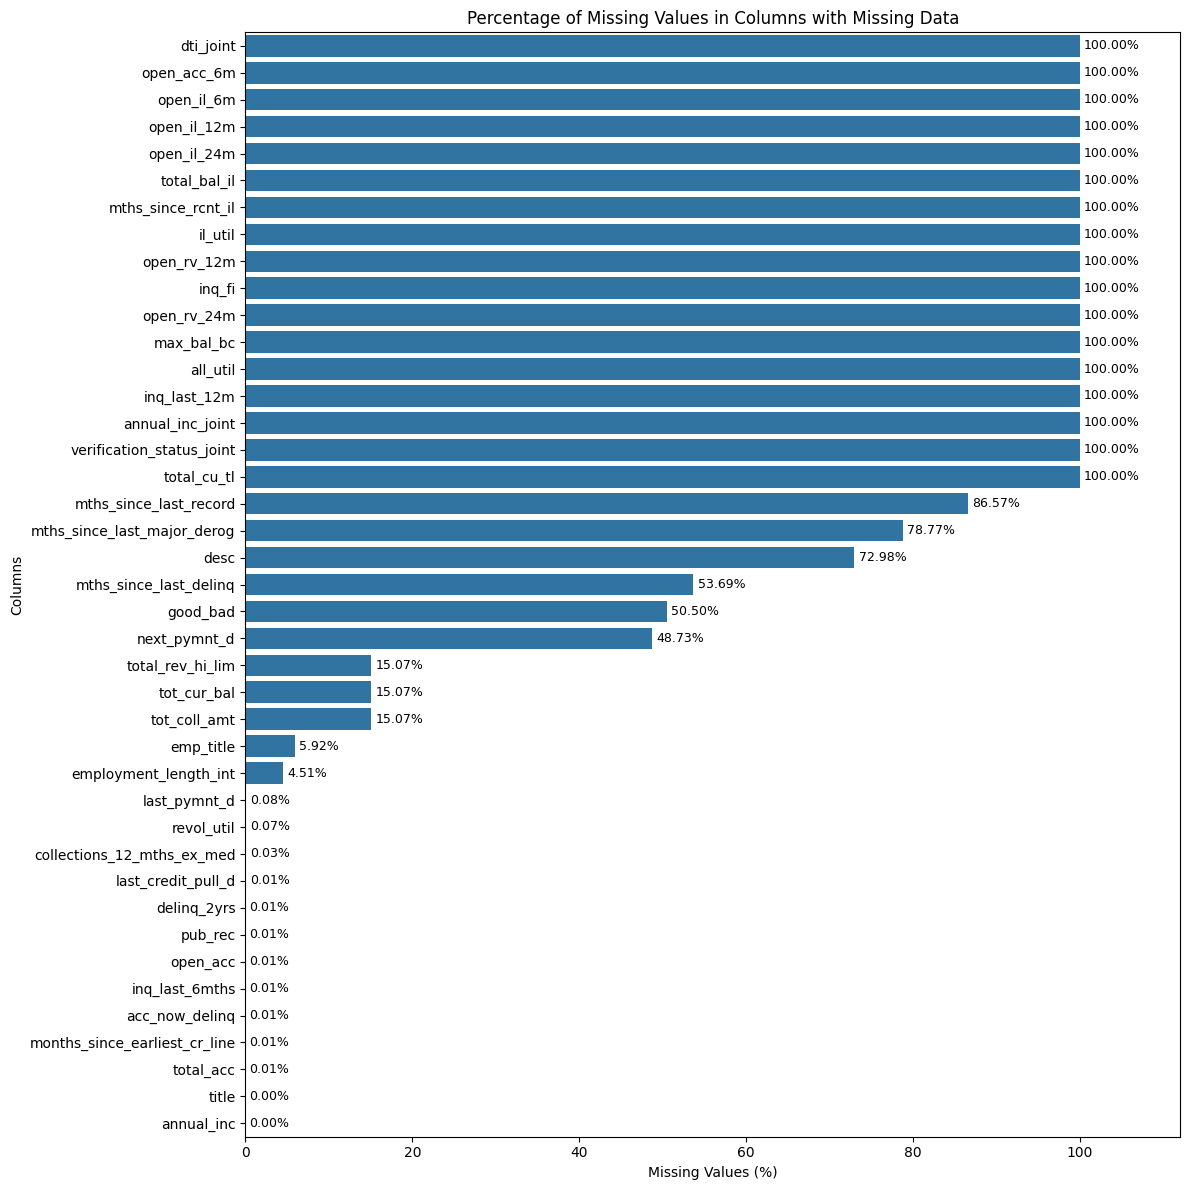

In [340]:
# Calculate missing values for each column
null_summary = pd.DataFrame({
    'Missing_Values': df_processed.isnull().sum(),
    'Missing_Percentage': (df_processed.isnull().sum() / df_processed.shape[0]) * 100
})

# Sort columns by missing percentage (highest first)
null_summary = null_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

# plot:
null_summary_nonzero = null_summary[
    null_summary['Missing_Values'] > 0
]

plt.figure(figsize=(12, 12))

ax = sns.barplot(
    x=null_summary_nonzero['Missing_Percentage'],
    y=null_summary_nonzero.index
)

ax.bar_label(
    ax.containers[0],
    fmt='%.2f%%',
    padding=3,
    fontsize=9
)

plt.title('Percentage of Missing Values in Columns with Missing Data')
plt.xlabel('Missing Values (%)')
plt.ylabel('Columns')
plt.xlim(0, null_summary_nonzero['Missing_Percentage'].max() * 1.12)
plt.tight_layout()
plt.show()


In [341]:
# retain information about which applicants originally had missing income data

# df_processed['annual_inc_missing'] = (
#     df_processed['annual_inc'].isnull().astype(int)
# )

# This indicator is 1 when annual_inc is missing and 0 otherwise.

# (null_summary.index != 'annual_inc') # excluding selected columns by user 'annual_inc'

# In credit risk datasets, missing information can sometimes be informative.
# For example, applicants with missing income information might have a different default risk from applicants who reported their income.

# in this level of this project we drop also the annual_inc null rows with the 5% bellow code.

In [342]:
# Set the missing-value threshold (%)
missing_threshold = 60

# Identify columns exceeding the threshold
columns_to_drop = null_summary[
    null_summary['Missing_Percentage'] > missing_threshold
].index

# Display columns to be dropped
print(f"Columns with more than {missing_threshold}% missing values for Drop columns:")
print(columns_to_drop.tolist())

# Store the original DataFrame shape
shape_before = df_processed.shape

# Drop columns
df_processed.drop(columns=columns_to_drop, inplace=True)

# Store the updated DataFrame shape
shape_after = df_processed.shape

# Calculate the difference
shape_difference = (
    shape_before[0] - shape_after[0],
    shape_before[1] - shape_after[1]
)

# Display results
print("\nDataFrame shape before:", shape_before)
print("DataFrame shape after: ", shape_after)
print("Shape difference:      ", shape_difference)


Columns with more than 60% missing values for Drop columns:
['dti_joint', 'open_acc_6m', 'open_il_6m', 'open_il_12m', 'open_il_24m', 'total_bal_il', 'mths_since_rcnt_il', 'il_util', 'open_rv_12m', 'inq_fi', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_last_12m', 'annual_inc_joint', 'verification_status_joint', 'total_cu_tl', 'mths_since_last_record', 'mths_since_last_major_derog', 'desc']

DataFrame shape before: (466285, 97)
DataFrame shape after:  (466285, 77)
Shape difference:       (0, 20)


In [343]:
# Set the missing-value threshold (%)
low_missing_threshold = 5

# Identify columns with missing percentages below the threshold
columns_to_check = null_summary[
    (null_summary['Missing_Percentage'] > 0) &
    (null_summary['Missing_Percentage'] < low_missing_threshold)
].index

# Display columns with less than 5% missing values
print(f"Columns with less than {low_missing_threshold}% missing values for Drop rows:")
print(columns_to_check.tolist())

# Store the original DataFrame shape
shape_before = df_processed.shape

# Drop rows containing null values in these columns
df_processed.dropna(subset=columns_to_check, inplace=True)

# Store the updated DataFrame shape
shape_after = df_processed.shape

# Calculate the difference
shape_difference = (
    shape_before[0] - shape_after[0],
    shape_before[1] - shape_after[1]
)

# Display results
print("\nDataFrame shape before:", shape_before)
print("DataFrame shape after: ", shape_after)
print("Shape difference:      ", shape_difference)


Columns with less than 5% missing values for Drop rows:
['employment_length_int', 'last_pymnt_d', 'revol_util', 'collections_12_mths_ex_med', 'last_credit_pull_d', 'delinq_2yrs', 'pub_rec', 'open_acc', 'inq_last_6mths', 'acc_now_delinq', 'months_since_earliest_cr_line', 'total_acc', 'title', 'annual_inc']

DataFrame shape before: (466285, 77)
DataFrame shape after:  (444432, 77)
Shape difference:       (21853, 0)


In [344]:
columns_with_missing = df_processed.columns[df_processed.isnull().any()].tolist()

print(columns_with_missing)
print(len(columns_with_missing))


['emp_title', 'mths_since_last_delinq', 'next_pymnt_d', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'good_bad']
7


In [345]:
df_processed['total_rev_hi_lim'] = (
    df_processed['total_rev_hi_lim']
    .fillna(df_processed['funded_amnt'])
)


In [346]:
df_processed['emp_title'] = df_processed['emp_title'].fillna('Unknown')

In [358]:
display(df_processed[columns_with_missing].sample(5, random_state=42))


,emp_title,mths_since_last_delinq,next_pymnt_d,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,good_bad
204339,Miami Dade Public Library,NaN,NaN,NaN,NaN,7000.0,0.0
108184,Sutter MS - Lausd,NaN,NaN,0.0,61842.0,28100.0,0.0
334454,Medical Assistant,NaN,Jan-16,122.0,78866.0,8100.0,NaN
22357,Columbia College Chicago,58.0,NaN,NaN,NaN,6400.0,1.0
401337,Computer Programmer,NaN,NaN,0.0,224396.0,58400.0,1.0


In [348]:
# ??? what to do for these columns missing values.

# skewness 
# heat map
# ox plot

In [349]:
num_df_processed = df_processed.select_dtypes(exclude="object")
cat_df_processed = df_processed.select_dtypes(include="object")

num_cols_df_processed = df_processed.select_dtypes(include="number").columns
cat_cols_df_processed = df_processed.select_dtypes(include="object").columns

print(num_cols_df_processed)
print(cat_cols_df_processed)


Index(['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt',
       'funded_amnt_inv', 'int_rate', 'installment', 'annual_inc', 'dti',
       'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_amnt',
       'collections_12_mths_ex_med', 'policy_code', 'acc_now_delinq',
       'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim',
       'employment_length_int', 'months_since_earliest_cr_line', 'term_int',
       'mths_since_issue_d', 'grade_rank', 'sub_grade_rank',
       'home_ownership:ANY', 'home_ownership:MORTGAGE', 'home_ownership:NONE',
       'home_ownership:OTHER', 'home_ownership:OWN', 'home_ownership:RENT',
       'verification_status:Not Verified',
       'verification_status:Source Verified', 'verifica

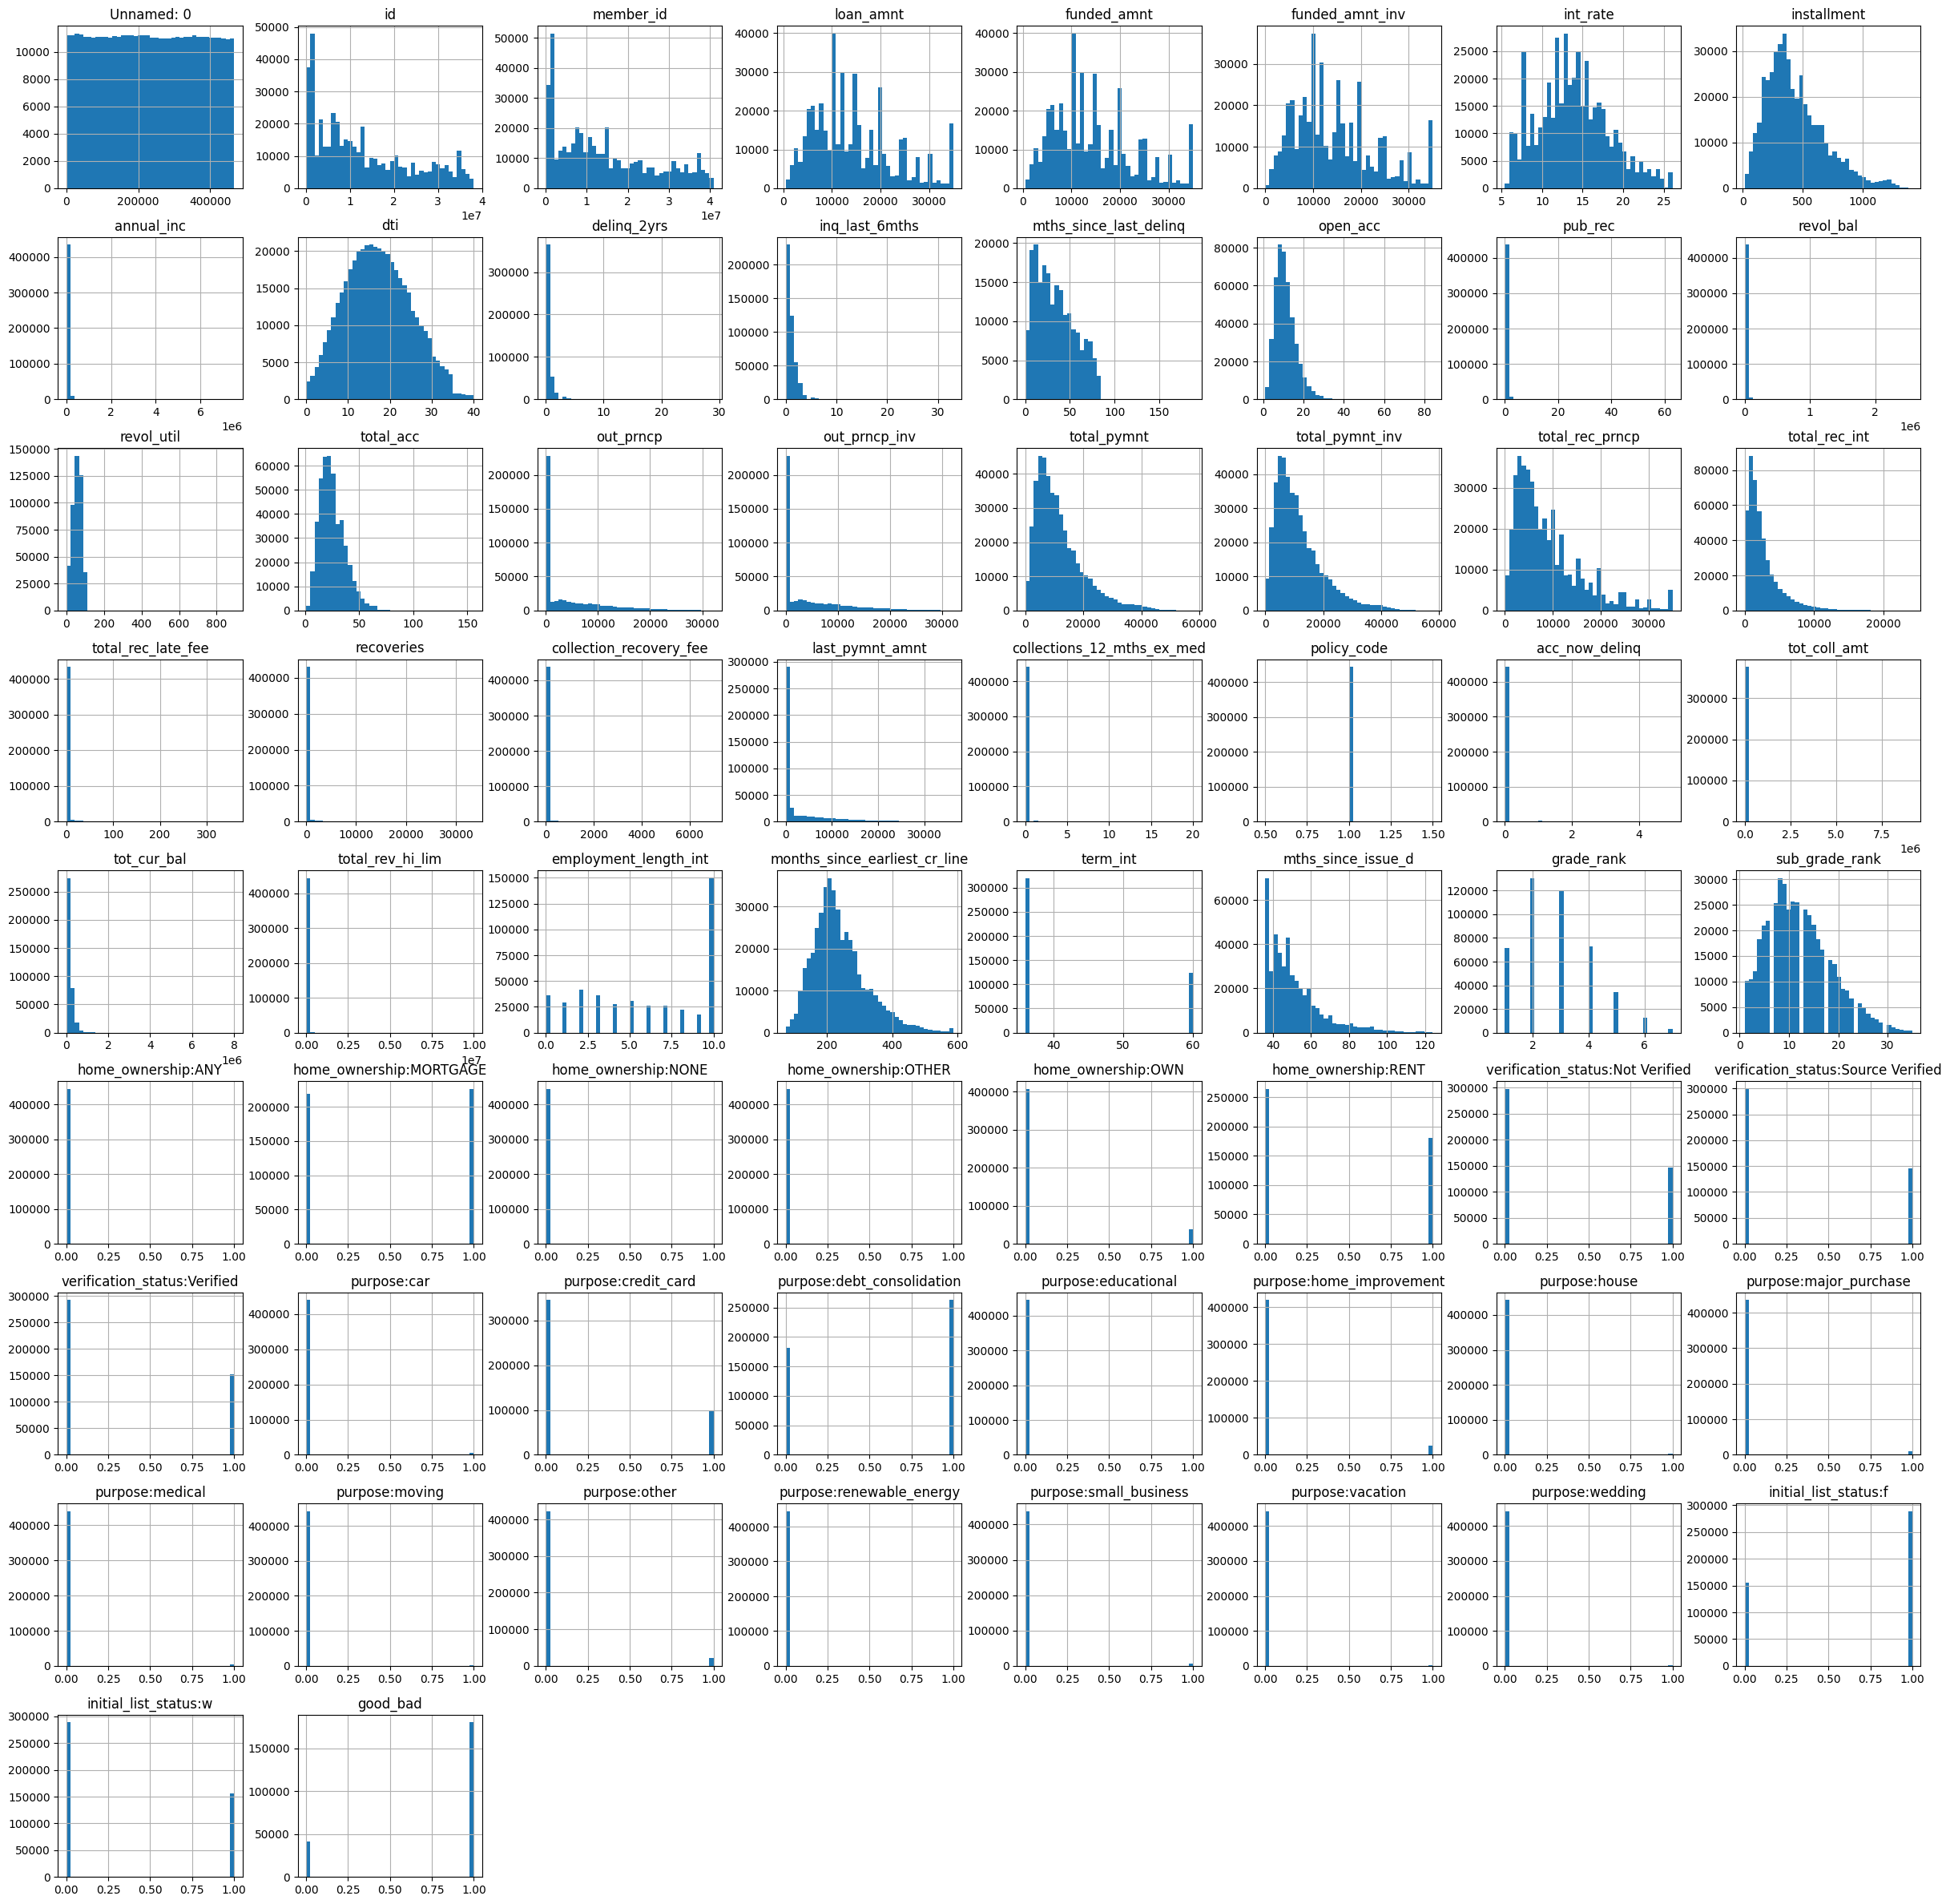

In [350]:
df_processed[num_cols_df_processed].hist(bins=40, figsize=(30, 30))
plt.show()


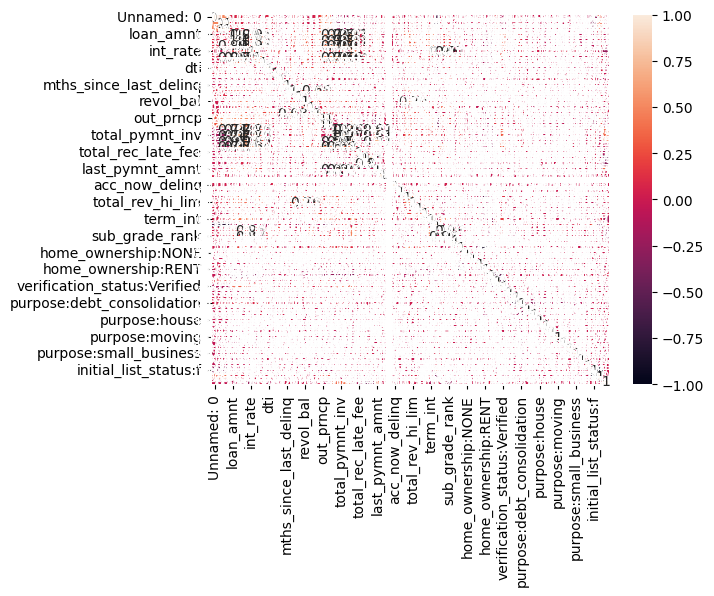

<Figure size 2000x2000 with 0 Axes>

In [351]:
sns.heatmap(df_processed[num_cols_df_processed].corr(), annot=True)
plt.figure(figsize=(20, 20))
plt.show()


# ===================================
# ======
# ================================
# ==========
# ==================================

In [352]:
# The training data is used to develop the model and determine preprocessing rules.
# The test data is reserved for final evaluation.

In [353]:
from sklearn.model_selection import train_test_split

# X_train, X_test, y_train, y_test = train_test_split(
#    X, y, test_size=0.25, random_state=42, stratify=y
#)



## Logistic regression
The logistic model represents log-odds as a linear combination of predictors:
logit(p) = ln(p / (1 - p)) = β0 + β1*x1 + ... + βk*xk
p = 1 / (1 + exp(-z))
Here p is the modeled probability of the event coded as 1. If the model instead predicts good = 1, default probability is 1 − p. Always verify which event is modeled.


In [354]:
# amzing morakdowm for the part that i choose model
# in this eample when i wan to use the logistic regression it is good to have goood markdoen and explain the the model detaild and foundamental


In [ ]:
# Retain only loans with clearly defined good/bad outcomes.
df_model = df_processed.loc[
    df_processed["good_bad"].isin([0, 1])
].copy()

# Define default as the positive event.
df_model["default"] = (
    1 - df_model["good_bad"].astype(int)
)

print("Modeling dataset shape:", df_model.shape)

print("\nDefault target distribution:")
print(df_model["default"].value_counts().sort_index())

print("\nDefault target percentages:")
print(
    df_model["default"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print(
    "\nObserved default rate:",
    round(df_model["default"].mean() * 100, 2),
    "%"
)


# ??? here we cahnge the 0 and 1 of the good and bad values to 0 and 1 of "default" value  (1 for default and 0 for non-default)
# we creat default column


# ??? this sentence is important that chat gpt say in bellow of this courese in project gpt
# The resulting dataset excludes unresolved loan statuses. That is a reasonable starting point for a binary model, but the treatment of early delinquencies and the definition of the performance window should ultimately match your intended credit-risk use case.

Modeling dataset shape: (221326, 78)

Default target distribution:
default
0    180071
1     41255
Name: count, dtype: int64

Default target percentages:
default
0    81.36
1    18.64
Name: proportion, dtype: float64

Observed default rate: 18.64 %


In [363]:
df_model.columns

Index(['Unnamed: 0', 'id', 'member_id', 'loan_amnt', 'funded_amnt',
       'funded_amnt_inv', 'int_rate', 'installment', 'emp_title', 'annual_inc',
       'loan_status', 'pymnt_plan', 'url', 'title', 'zip_code', 'addr_state',
       'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq',
       'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv',
       'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt',
       'tot_cur_bal', 'total_rev_hi_lim', 'employment_length_int',
       'months_since_earliest_cr_line', 'term_int', 'mths_since_issue_d',
       'grade_rank', 'sub_grade_rank', 'home_ownership:ANY',
       'home_ownership:MORTGAGE', 'home_ownership:NONE',
  

In [367]:
df_model.shape

(221326, 78)

In [365]:
# Predictors selected for the initial PD model.
# Include only variables available at the intended prediction time.

candidate_features = [
    # Loan characteristics
    "loan_amnt",
    "term_int",
    "int_rate",
    "installment",
    "grade_rank",

    # Borrower profile
    "employment_length_int",
    "annual_inc",

    # One-hot encoded home ownership
    "home_ownership:ANY",
    "home_ownership:MORTGAGE",
    "home_ownership:NONE",
    "home_ownership:OTHER",
    "home_ownership:OWN",
    "home_ownership:RENT",

    # One-hot encoded verification status
    "verification_status:Not Verified",
    "verification_status:Source Verified",
    "verification_status:Verified",

    # One-hot encoded loan purpose
    "purpose:car",
    "purpose:credit_card",
    "purpose:debt_consolidation",
    "purpose:educational",
    "purpose:home_improvement",
    "purpose:house",
    "purpose:major_purchase",
    "purpose:medical",
    "purpose:moving",
    "purpose:other",
    "purpose:renewable_energy",
    "purpose:small_business",
    "purpose:vacation",
    "purpose:wedding",

    # One-hot encoded initial listing status
    "initial_list_status:f",
    "initial_list_status:w",

    # Credit history and indebtedness
    "dti",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "acc_now_delinq",
    "tot_coll_amt",
    "tot_cur_bal",
    "total_rev_hi_lim",
    "months_since_earliest_cr_line",
]

# Keep only columns that actually exist in df_model.
features = [
    col for col in candidate_features
    if col in df_model.columns
]

# Identify any missing candidate columns.
missing_candidates = [
    col for col in candidate_features
    if col not in df_model.columns
]

print("Selected predictors:")
print(features)

print("\nCandidate predictors not found in the dataset:")
print(missing_candidates)

print("\nNumber of selected predictors:", len(features))

Selected predictors:
['loan_amnt', 'term_int', 'int_rate', 'installment', 'grade_rank', 'employment_length_int', 'annual_inc', 'home_ownership:ANY', 'home_ownership:MORTGAGE', 'home_ownership:NONE', 'home_ownership:OTHER', 'home_ownership:OWN', 'home_ownership:RENT', 'verification_status:Not Verified', 'verification_status:Source Verified', 'verification_status:Verified', 'purpose:car', 'purpose:credit_card', 'purpose:debt_consolidation', 'purpose:educational', 'purpose:home_improvement', 'purpose:house', 'purpose:major_purchase', 'purpose:medical', 'purpose:moving', 'purpose:other', 'purpose:renewable_energy', 'purpose:small_business', 'purpose:vacation', 'purpose:wedding', 'initial_list_status:f', 'initial_list_status:w', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'months_since_earliest_cr_line']

Candidate predictors not found in the dataset:
[]

Number of

In [369]:
assert len(features) > 0, "No predictors were found."

print(df_model[features].dtypes)

display(df_model[features].sample(5, random_state=42))

loan_amnt                                int64
term_int                                 Int64
int_rate                               float64
installment                            float64
grade_rank                               int64
employment_length_int                    Int64
annual_inc                             float64
home_ownership:ANY                        int8
home_ownership:MORTGAGE                   int8
home_ownership:NONE                       int8
home_ownership:OTHER                      int8
home_ownership:OWN                        int8
home_ownership:RENT                       int8
verification_status:Not Verified          int8
verification_status:Source Verified       int8
verification_status:Verified              int8
purpose:car                               int8
purpose:credit_card                       int8
purpose:debt_consolidation                int8
purpose:educational                       int8
purpose:home_improvement                  int8
purpose:house

,loan_amnt,term_int,int_rate,installment,grade_rank,employment_length_int,annual_inc,home_ownership:ANY,home_ownership:MORTGAGE,home_ownership:NONE,home_ownership:OTHER,home_ownership:OWN,home_ownership:RENT,verification_status:Not Verified,verification_status:Source Verified,verification_status:Verified,purpose:car,purpose:credit_card,purpose:debt_consolidation,purpose:educational,purpose:home_improvement,purpose:house,purpose:major_purchase,purpose:medical,purpose:moving,purpose:other,purpose:renewable_energy,purpose:small_business,purpose:vacation,purpose:wedding,initial_list_status:f,initial_list_status:w,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,acc_now_delinq,tot_coll_amt,tot_cur_bal,total_rev_hi_lim,months_since_earliest_cr_line
368320,15700,60,20.99,424.65,5,10,43800.0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,28.03,0.0,0.0,15.0,0.0,27837,66.3,23.0,0.0,0.0,33887.0,42000.0,234.0
213107,2000,36,13.67,68.04,2,3,28000.0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,12.29,0.0,0.0,8.0,0.0,6951,63.8,11.0,0.0,NaN,NaN,2000.0,199.0
29215,5500,36,10.38,178.46,2,4,27996.0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,14.92,0.0,1.0,9.0,0.0,1253,19.9,15.0,0.0,NaN,NaN,5500.0,161.0
147221,9750,36,19.72,360.96,4,1,28838.4,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,24.88,0.0,2.0,12.0,0.0,5901,47.2,40.0,0.0,0.0,15033.0,12500.0,215.0
213353,13475,36,16.29,475.68,3,10,120000.0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,4.28,0.0,1.0,7.0,0.0,4059,73.8,8.0,0.0,NaN,NaN,13475.0,405.0


In [372]:
# Features and target.
X = df_model[features].copy()

# Positive class = default.
y = df_model["default"].copy()

# Split before learning imputation values, scaling parameters,
# WoE bins, or other data-dependent preprocessing rules.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\n'Training' target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\n'Test' target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training features: (165994, 45)
Test features: (55332, 45)

'Training' target distribution:
default
0    0.813602
1    0.186398
Name: proportion, dtype: float64

'Test' target distribution:
default
0    0.813598
1    0.186402
Name: proportion, dtype: float64


In [373]:
target_distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
    "Full sample": y.value_counts(normalize=True)
}).sort_index()

target_distribution.index.name = "Default"

display(target_distribution)

print("\nTraining default rate:", round(y_train.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))

,Training,Test,Full sample
Default,,,
0,0.813602,0.813598,0.813601
1,0.186398,0.186402,0.186399



Training default rate: 0.1864
Test default rate: 0.1864


In [374]:
# Identify numerical and categorical features.

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['loan_amnt', 'term_int', 'int_rate', 'installment', 'grade_rank', 'employment_length_int', 'annual_inc', 'home_ownership:ANY', 'home_ownership:MORTGAGE', 'home_ownership:NONE', 'home_ownership:OTHER', 'home_ownership:OWN', 'home_ownership:RENT', 'verification_status:Not Verified', 'verification_status:Source Verified', 'verification_status:Verified', 'purpose:car', 'purpose:credit_card', 'purpose:debt_consolidation', 'purpose:educational', 'purpose:home_improvement', 'purpose:house', 'purpose:major_purchase', 'purpose:medical', 'purpose:moving', 'purpose:other', 'purpose:renewable_energy', 'purpose:small_business', 'purpose:vacation', 'purpose:wedding', 'initial_list_status:f', 'initial_list_status:w', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'months_since_earliest_cr_line']

Categorical features:
[]


In [391]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    brier_score_loss
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)

from sklearn.metrics import roc_curve



In [378]:
# Import the required libraries.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Define the numerical features.
# This includes both ordinary numerical variables and
# one-hot encoded categorical variables.
numeric_features = candidate_features

# Create the preprocessing pipeline.
preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Select the features and target.
X = df_model[numeric_features].copy()
y = df_model["default"].copy()

print("Number of features:", len(numeric_features))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Check that all selected features are numeric.
print("\nNon-numeric features:")
print(X.select_dtypes(exclude="number").columns.tolist())

Number of features: 45
Feature matrix shape: (221326, 45)
Target shape: (221326,)

Non-numeric features:
[]


In [379]:
# Split the data into training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [380]:
# Create the complete modeling pipeline.
pd_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

# Fit using training data only.
pd_model.fit(X_train, y_train)

print("Logistic regression model fitted successfully.")

Logistic regression model fitted successfully.


In [383]:
# Predicted probabilities.
y_train_pd = pd_model.predict_proba(X_train)[:, 1]
y_test_pd = pd_model.predict_proba(X_test)[:, 1]

# Predicted classes using the default 0.50 threshold.
y_train_pred = pd_model.predict(X_train)
y_test_pred = pd_model.predict(X_test)

# Store test results for analysis.
test_results = pd.DataFrame({
    "actual_default": y_test.to_numpy(),
    "predicted_default": y_test_pred,
    "predicted_PD": y_test_pd
}, index=y_test.index)

display(test_results.head(10))

,actual_default,predicted_default,predicted_PD
164837,0,0,0.104536
212388,0,0,0.080744
381281,0,0,0.037132
139565,0,0,0.217801
145669,0,0,0.058267
351775,0,0,0.122136
205550,0,0,0.308192
215565,1,0,0.214370
37501,0,0,0.128145
133198,0,0,0.321226


In [ ]:
# above code comments:

The predict_proba() method returns the estimated probability of each class.

Because our positive class is default = 1, the expression:

pd_model.predict_proba(X_test)[:, 1]

returns the estimated probability of default for each test observation.

For example, a predicted PD of 0.12 means the model estimates a 12% probability of default for that observation, conditional on the selected predictors and the fitted model.

It does not mean that the borrower will necessarily default.

### Step 8. Evaluate the model
Accuracy alone is not sufficient for credit-risk modeling. The following metrics measure different aspects of model performance.

### 8.1 Confusion matrix and classification report
Interpretation:
- True negative: A non-default borrower correctly classified as non-default.
- False positive: A non-default borrower incorrectly classified as default.
- False negative: A defaulting borrower incorrectly classified as non-default.
- True positive: A defaulting borrower correctly classified as default.
In credit-risk applications, false negatives can be particularly costly because they represent defaults that the model failed to identify.

However, the appropriate decision threshold depends on the institution's risk appetite, lending policy, and the costs of different errors.

In [384]:
# Confusion matrix on the test set.
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual non-default",
        "Actual default"
    ],
    columns=[
        "Predicted non-default",
        "Predicted default"
    ]
)

display(cm_df)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Non-default", "Default"],
        zero_division=0
    )
)

,Predicted non-default,Predicted default
Actual non-default,44452,566
Actual default,9734,580



Classification report:
              precision    recall  f1-score   support

 Non-default       0.82      0.99      0.90     45018
     Default       0.51      0.06      0.10     10314

    accuracy                           0.81     55332
   macro avg       0.66      0.52      0.50     55332
weighted avg       0.76      0.81      0.75     55332



### 8.2 Calculate evaluation metrics
The metrics have different interpretations:

| Metric | What it measures |
|---|---|
| Accuracy | Overall proportion of correctly classified observations |
| Precision | Proportion of predicted defaults that actually defaulted |
| Recall | Proportion of actual defaults identified by the model |
| F1 score | Balance between precision and recall |
| ROC-AUC | Ability to rank defaults above non-defaults |
| Brier score | Mean squared error of predicted probabilities |

A lower Brier score is better, but its interpretation depends on the underlying default rate. A good ROC-AUC does not guarantee that predicted probabilities are well calibrated.

In [387]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),

    "Precision": precision_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "F1 Score": f1_score(
        y_test,
        y_test_pred,
        zero_division=0
    ),

    "ROC-AUC": roc_auc_score(
        y_test,
        y_test_pd
    ),

    "Brier Score": brier_score_loss(
        y_test,
        y_test_pd
    )
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Value"]
)

display(metrics_df)

,Metric,Value
0,Accuracy,0.813851
1,Precision,0.506108
2,Recall,0.056234
3,F1 Score,0.101222
4,ROC-AUC,0.705803
5,Brier Score,0.138818


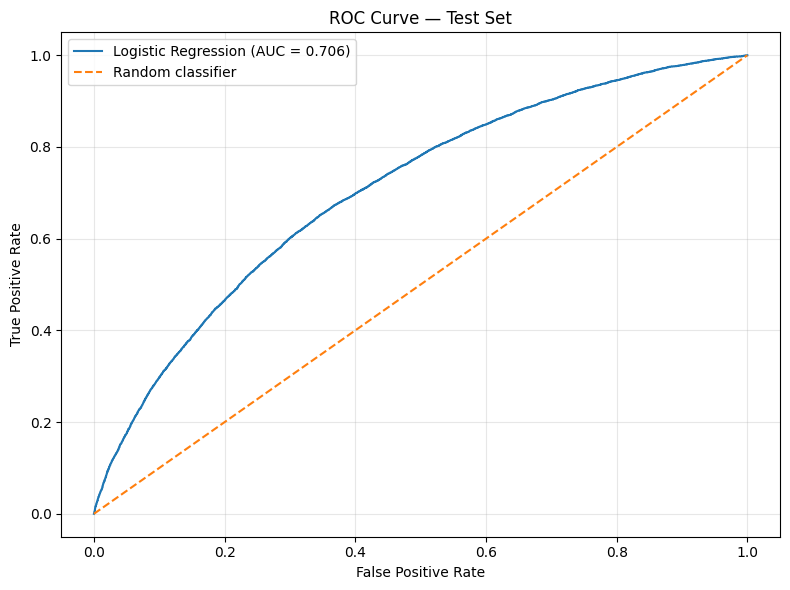

In [392]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_pd
)

auc_value = roc_auc_score(
    y_test,
    y_test_pd
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_value:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# The ROC curve shows how the true positive rate and false positive rate change as the classification threshold changes.

# ROC-AUC measures ranking ability. It does not directly tell you whether a predicted PD of 10% corresponds to an observed default frequency of approximately 10%.

In [394]:
from sklearn.calibration import CalibrationDisplay

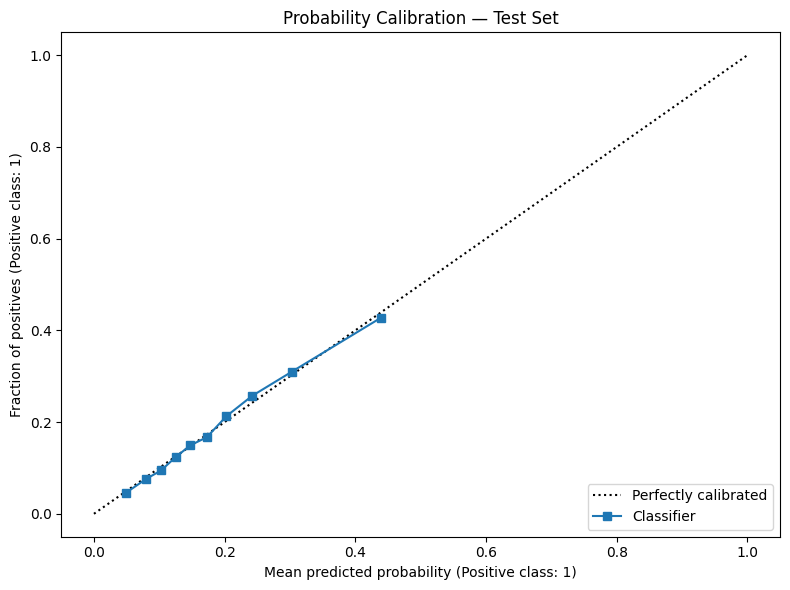

In [395]:
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    y_test_pd,
    n_bins=10,
    strategy="quantile",
    ax=ax
)

ax.set_title("Probability Calibration — Test Set")
plt.tight_layout()
plt.show()

In [ ]:
# A well-calibrated model should, approximately, predict a 10% default probability for groups of borrowers in which about 10% subsequently default.

# Calibration can be particularly important when PD estimates are used in credit decisions or risk calculations.

# If the model will be used operationally, assess calibration on appropriate validation data and consider whether recalibration is necessary.

In [ ]:
# in chat gpt help coding in the {C R - 31 oct}
# countinue from here:
# Topic 7 — Fine Classing, Coarse Classing, WoE and IV